In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv('Student_Behaviour_Dirty_Practice.csv')
cdf=df.copy()

In [4]:
cdf.head()

,StudentID,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct,SleepHours,ScreenTimeHours,Gender,Stream,ExtraCurricular,Age,BacklogCount,OptionalCounsellorNote,OptionalHostelBlock
0,S2158,4.5,97.0,84,88.9,7.5,2.8,Male,COMMERCE,No,21.0,0,NaN,NaN
1,S2249,5.6,93.1,80,87.3,8.0,2.6,Male,Science,No,17.0,0,NaN,NaN
2,S2146,2.0,76.8,64,76.0,7.2,3.0,Male,Commerce,Yes,21.0,1,NaN,NaN
3,S2297,1.6,88.2,68,87.5,7.4,6.0,Male,Commerce,No,22.0,1,NaN,NaN
4,S2232,4.6,93.5,85,89.9,6.9,1.7,Male,Commerce,Yes,20.0,0,NaN,NaN


In [5]:
cdf.shape

(415, 14)

In [6]:
cdf.describe()

,AssignmentCompletionPct,SleepHours,ScreenTimeHours,Age,BacklogCount
count,400.000000,399.000000,400.000000,403.000000,415.000000
mean,69.210750,6.522055,5.032250,20.096774,1.125301
std,19.955059,1.029546,2.712818,4.513448,1.483797
min,19.700000,3.800000,0.800000,3.000000,0.000000
25%,51.775000,5.800000,2.900000,18.000000,0.000000
50%,73.800000,6.600000,4.600000,20.000000,1.000000
75%,86.175000,7.300000,6.825000,22.000000,2.000000
max,100.000000,9.000000,22.000000,99.000000,8.000000


In [7]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   StudentID                415 non-null    object 
 1   StudyHoursPerDay         414 non-null    object 
 2   AttendancePct            415 non-null    object 
 3   PrevExamScore            415 non-null    object 
 4   AssignmentCompletionPct  400 non-null    float64
 5   SleepHours               399 non-null    float64
 6   ScreenTimeHours          400 non-null    float64
 7   Gender                   415 non-null    object 
 8   Stream                   415 non-null    object 
 9   ExtraCurricular          415 non-null    object 
 10  Age                      403 non-null    float64
 11  BacklogCount             415 non-null    int64  
 12  OptionalCounsellorNote   21 non-null     object 
 13  OptionalHostelBlock      21 non-null     object 
dtypes: float64(4), int64(1), o

In [8]:
print("Missing Values Count")
print('\n\n')
print(cdf.isna().sum())

print('\n\n Missing values percentage ')

(cdf.isna().sum()/len(cdf)*100).round(2)

Missing Values Count



StudentID                    0
StudyHoursPerDay             1
AttendancePct                0
PrevExamScore                0
AssignmentCompletionPct     15
SleepHours                  16
ScreenTimeHours             15
Gender                       0
Stream                       0
ExtraCurricular              0
Age                         12
BacklogCount                 0
OptionalCounsellorNote     394
OptionalHostelBlock        394
dtype: int64


 Missing values percentage 


StudentID                   0.00
StudyHoursPerDay            0.24
AttendancePct               0.00
PrevExamScore               0.00
AssignmentCompletionPct     3.61
SleepHours                  3.86
ScreenTimeHours             3.61
Gender                      0.00
Stream                      0.00
ExtraCurricular             0.00
Age                         2.89
BacklogCount                0.00
OptionalCounsellorNote     94.94
OptionalHostelBlock        94.94
dtype: float64

In [9]:

print("Duplicated Values")
print('\n')
print(cdf.duplicated().value_counts())
print('\n')
print("Total Number Duplicate Value :",cdf.duplicated().sum())

print('\n\n Duplicate values percentage ')

(cdf.duplicated().value_counts()/len(cdf)*100).round(2)

Duplicated Values


False    400
True      15
Name: count, dtype: int64


Total Number Duplicate Value : 15


 Duplicate values percentage 


False    96.39
True      3.61
Name: count, dtype: float64

In [10]:
cols = ['StudyHoursPerDay', 'AttendancePct', 'PrevExamScore']

for col in cols:
    # strip units/text first so valid values like "3.5 hrs" and "78%" are kept
    cdf[col] = (cdf[col].astype(str)
                        .str.replace('hrs', '', regex=False)
                        .str.replace('%', '', regex=False)
                        .str.strip())
    # now only real junk ("N/A", "?", "none", "absent", "--") becomes NaN
    cdf[col] = pd.to_numeric(cdf[col], errors='coerce')

print(cdf[cols].isna().sum())

numericalcols = cdf.select_dtypes(include=['float64', 'int64']).columns
print("numerical columns :", numericalcols)

StudyHoursPerDay    8
AttendancePct       0
PrevExamScore       9
dtype: int64
numerical columns : Index(['StudyHoursPerDay', 'AttendancePct', 'PrevExamScore',
       'AssignmentCompletionPct', 'SleepHours', 'ScreenTimeHours', 'Age',
       'BacklogCount'],
      dtype='object')


In [11]:
numericalcols=cdf.select_dtypes(include=['float64','int64']).columns
print("numerical columns :",numericalcols)

print('\n\n')
caategorical_col=cdf.select_dtypes(include=['object','string']).columns
print("categorical Columns :",caategorical_col)

numerical columns : Index(['StudyHoursPerDay', 'AttendancePct', 'PrevExamScore',
       'AssignmentCompletionPct', 'SleepHours', 'ScreenTimeHours', 'Age',
       'BacklogCount'],
      dtype='object')



categorical Columns : Index(['StudentID', 'Gender', 'Stream', 'ExtraCurricular',
       'OptionalCounsellorNote', 'OptionalHostelBlock'],
      dtype='object')


In [12]:
cdf.isna().sum()

StudentID                    0
StudyHoursPerDay             8
AttendancePct                0
PrevExamScore                9
AssignmentCompletionPct     15
SleepHours                  16
ScreenTimeHours             15
Gender                       0
Stream                       0
ExtraCurricular              0
Age                         12
BacklogCount                 0
OptionalCounsellorNote     394
OptionalHostelBlock        394
dtype: int64

***Handling Categorical Columns***

In [13]:
for col in cdf.columns:
    if(col in caategorical_col):
        cdf[col]=cdf[col].str.strip().str.title()

In [14]:
for col in cdf.columns:
    if(col in caategorical_col):
        print(cdf[col].value_counts())
        print('\n')


StudentID
S2241    2
S2047    2
S2367    2
S2312    2
S2320    2
        ..
S2368    1
S2244    1
S2377    1
S2032    1
S2313    1
Name: count, Length: 400, dtype: int64


Gender
Female    215
Male      193
F           4
M           3
Name: count, dtype: int64


Stream
Science        122
Engineering    113
Commerce       110
Arts            67
Engg             3
Name: count, dtype: int64


ExtraCurricular
No     233
Yes    177
Y        3
N        2
Name: count, dtype: int64


OptionalCounsellorNote
Needs Follow-Up    11
Family Issue        7
Motivated           3
Name: count, dtype: int64


OptionalHostelBlock
A    10
C     6
B     5
Name: count, dtype: int64




In [15]:
cdf['Gender']=cdf.Gender.replace({
    'F':'Female',
    'M':'Male'
})

cdf['ExtraCurricular']=cdf.ExtraCurricular.replace({
    'Y':'Yes',
    'N':'No'
})


***Recheking the Inconsistent data***

In [16]:
for col in cdf.columns:
    if(col in caategorical_col):
        print(cdf[col].value_counts())
        print('\n')


StudentID
S2241    2
S2047    2
S2367    2
S2312    2
S2320    2
        ..
S2368    1
S2244    1
S2377    1
S2032    1
S2313    1
Name: count, Length: 400, dtype: int64


Gender
Female    219
Male      196
Name: count, dtype: int64


Stream
Science        122
Engineering    113
Commerce       110
Arts            67
Engg             3
Name: count, dtype: int64


ExtraCurricular
No     235
Yes    180
Name: count, dtype: int64


OptionalCounsellorNote
Needs Follow-Up    11
Family Issue        7
Motivated           3
Name: count, dtype: int64


OptionalHostelBlock
A    10
C     6
B     5
Name: count, dtype: int64




***Handling Missing Values***

In [17]:
cdf=cdf.drop_duplicates()
cdf.duplicated().sum()

np.int64(0)

In [18]:
for col in cdf.columns:
    if(col in numericalcols):
        cdf[col]=cdf[col].fillna(cdf[col].median())
    elif(col in caategorical_col):
        cdf[col]=cdf[col].fillna(cdf[col].mode()[0])

cdf.isna().sum()

StudentID                  0
StudyHoursPerDay           0
AttendancePct              0
PrevExamScore              0
AssignmentCompletionPct    0
SleepHours                 0
ScreenTimeHours            0
Gender                     0
Stream                     0
ExtraCurricular            0
Age                        0
BacklogCount               0
OptionalCounsellorNote     0
OptionalHostelBlock        0
dtype: int64

In [19]:
cdf=cdf[cdf['PrevExamScore']>0]
cdf=cdf[cdf['AttendancePct']<101]

cdf.head()

,StudentID,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct,SleepHours,ScreenTimeHours,Gender,Stream,ExtraCurricular,Age,BacklogCount,OptionalCounsellorNote,OptionalHostelBlock
0,S2158,4.5,97.0,84.0,88.9,7.5,2.8,Male,Commerce,No,21.0,0,Needs Follow-Up,A
1,S2249,5.6,93.1,80.0,87.3,8.0,2.6,Male,Science,No,17.0,0,Needs Follow-Up,A
2,S2146,2.0,76.8,64.0,76.0,7.2,3.0,Male,Commerce,Yes,21.0,1,Needs Follow-Up,A
3,S2297,1.6,88.2,68.0,87.5,7.4,6.0,Male,Commerce,No,22.0,1,Needs Follow-Up,A
4,S2232,4.6,93.5,85.0,89.9,6.9,1.7,Male,Commerce,Yes,20.0,0,Needs Follow-Up,A


***EDA***

<Axes: xlabel='StudyHoursPerDay', ylabel='PrevExamScore'>

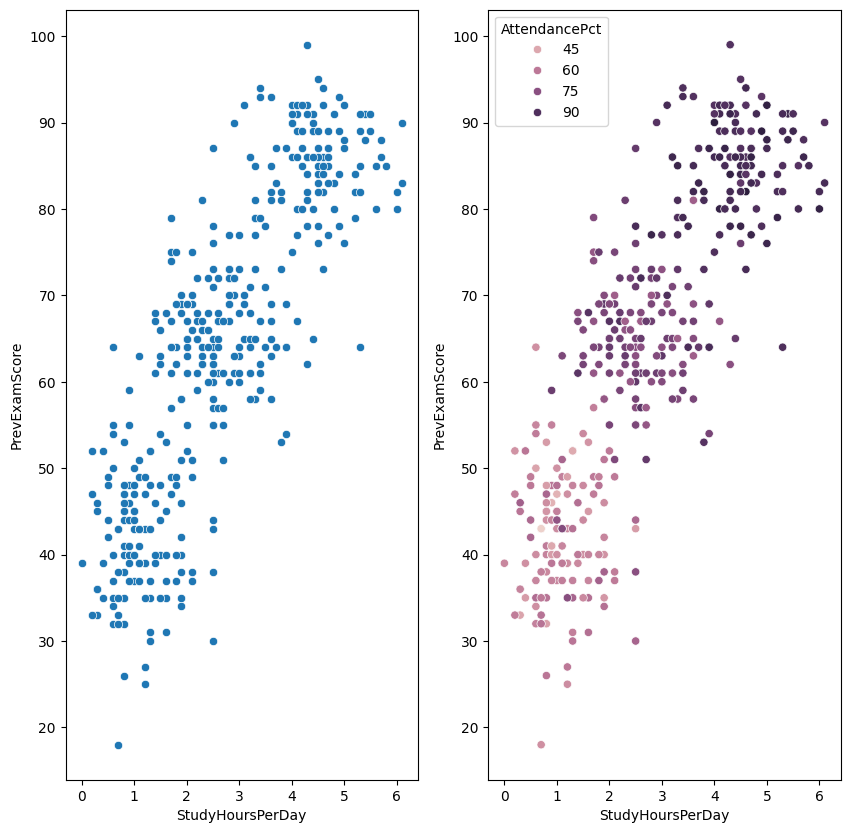

In [20]:
fig,axes=plt.subplots(1,2,figsize=(10,10))
sns.scatterplot(data=cdf,x='StudyHoursPerDay',y='PrevExamScore',ax=axes[0])


sns.scatterplot(data=cdf,x='StudyHoursPerDay',y='PrevExamScore',hue='AttendancePct',ax=axes[1])

<Axes: ylabel='AssignmentCompletionPct'>

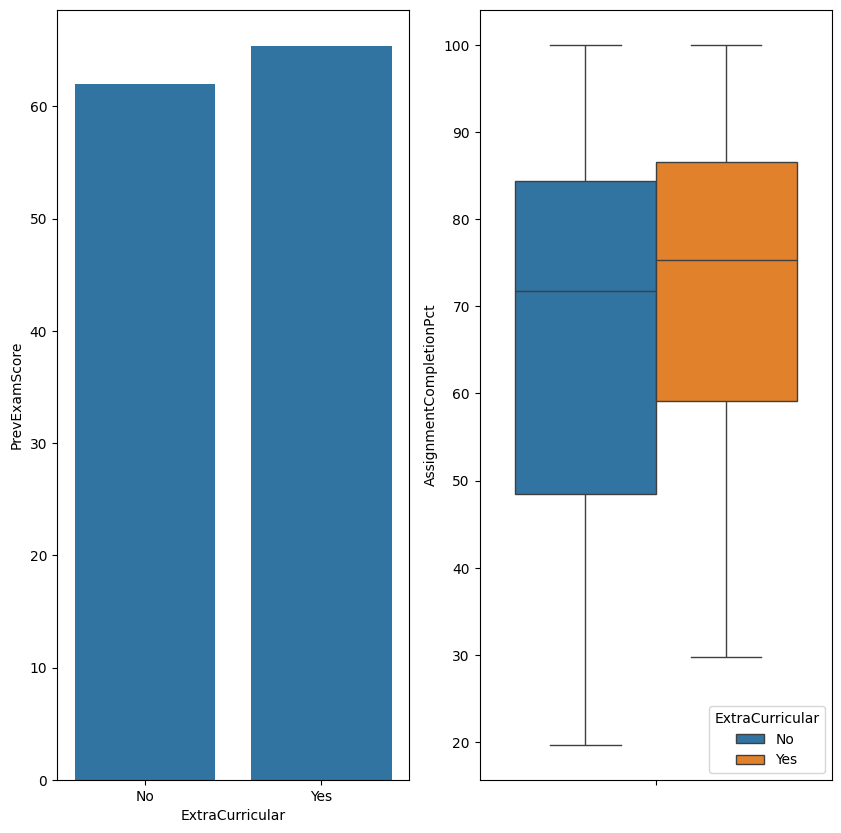

In [21]:
fig,axes=plt.subplots(1,2,figsize=(10,10))

sns.barplot(data=cdf,x='ExtraCurricular',y='PrevExamScore',ax=axes[0],errorbar=None)

sns.boxplot(data=cdf,y='AssignmentCompletionPct',hue='ExtraCurricular')

***Kmeans- Clustering***

In [22]:
cdf.head()

,StudentID,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct,SleepHours,ScreenTimeHours,Gender,Stream,ExtraCurricular,Age,BacklogCount,OptionalCounsellorNote,OptionalHostelBlock
0,S2158,4.5,97.0,84.0,88.9,7.5,2.8,Male,Commerce,No,21.0,0,Needs Follow-Up,A
1,S2249,5.6,93.1,80.0,87.3,8.0,2.6,Male,Science,No,17.0,0,Needs Follow-Up,A
2,S2146,2.0,76.8,64.0,76.0,7.2,3.0,Male,Commerce,Yes,21.0,1,Needs Follow-Up,A
3,S2297,1.6,88.2,68.0,87.5,7.4,6.0,Male,Commerce,No,22.0,1,Needs Follow-Up,A
4,S2232,4.6,93.5,85.0,89.9,6.9,1.7,Male,Commerce,Yes,20.0,0,Needs Follow-Up,A


In [23]:
cdf.corr(numeric_only=True)

,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct,SleepHours,ScreenTimeHours,Age,BacklogCount
StudyHoursPerDay,1.000000,0.826242,0.832631,0.791548,0.519784,-0.638162,0.037213,-0.446599
AttendancePct,0.826242,1.000000,0.865685,0.844888,0.558942,-0.683840,0.044569,-0.508267
PrevExamScore,0.832631,0.865685,1.000000,0.847400,0.583202,-0.670158,0.045592,-0.556574
AssignmentCompletionPct,0.791548,0.844888,0.847400,1.000000,0.561083,-0.666414,0.048507,-0.536569
SleepHours,0.519784,0.558942,0.583202,0.561083,1.000000,-0.458269,-0.015044,-0.427005
ScreenTimeHours,-0.638162,-0.683840,-0.670158,-0.666414,-0.458269,1.000000,-0.008102,0.390426
Age,0.037213,0.044569,0.045592,0.048507,-0.015044,-0.008102,1.000000,-0.033375
BacklogCount,-0.446599,-0.508267,-0.556574,-0.536569,-0.427005,0.390426,-0.033375,1.000000


In [24]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()
cdf['ExtraCurricular']=le.fit_transform(cdf['ExtraCurricular'])

In [25]:
X=cdf.drop(['StudentID','Gender','Stream','OptionalCounsellorNote','OptionalHostelBlock','ExtraCurricular','Age','BacklogCount','SleepHours','ScreenTimeHours'],axis=1)

In [26]:
X.corr(numeric_only=True)

,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct
StudyHoursPerDay,1.000000,0.826242,0.832631,0.791548
AttendancePct,0.826242,1.000000,0.865685,0.844888
PrevExamScore,0.832631,0.865685,1.000000,0.847400
AssignmentCompletionPct,0.791548,0.844888,0.847400,1.000000


In [27]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_scaled=scaler.fit_transform(X)


WCSS - Elbow Method

Text(0.5, 1.0, 'Elbow Method')

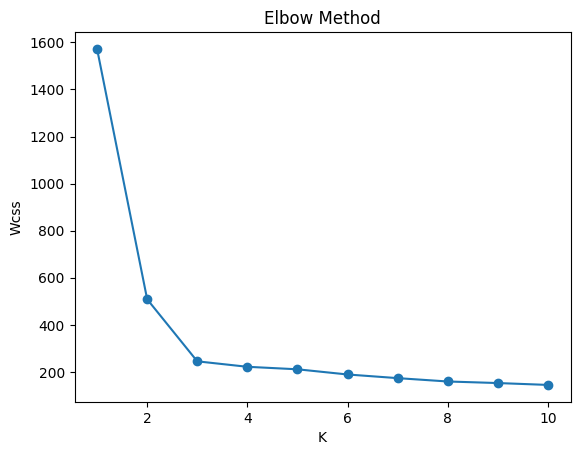

In [28]:
from sklearn.cluster import KMeans
wcss=[]

for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42,init='k-means++')
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11),wcss,marker='o')
plt.xlabel("K")
plt.ylabel("Wcss")
plt.title('Elbow Method')

***Shilouette Score***

In [29]:
from sklearn.metrics import silhouette_score
silhouette_scores=[]

for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42,init='k-means++')
    labels=kmeans.fit_predict(x_scaled)
    score=silhouette_score(x_scaled,labels)
    silhouette_scores.append(score)


print("Silhouette_Scores :",silhouette_scores)
print("best Silhoutee_score:",max(silhouette_scores))
print(silhouette_scores.index(max(silhouette_scores)))

Silhouette_Scores : [0.5814572445899463, 0.5518111914380255, 0.41160802203632635, 0.3979549074429145, 0.2923211025221108, 0.20789227132513882, 0.20651749135702993, 0.2127065226015479, 0.20975904349720392]
best Silhoutee_score: 0.5814572445899463
0


Text(0, 0.5, 'Silhoutee score')

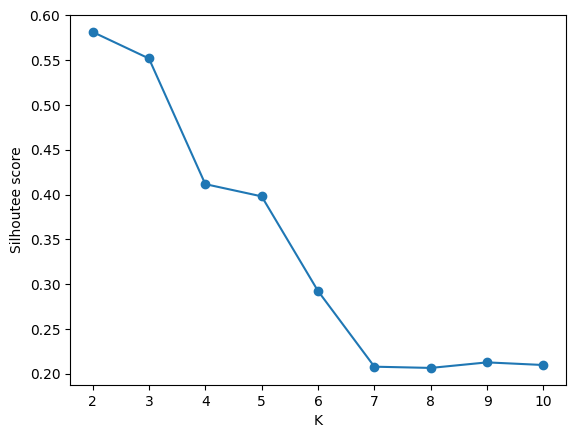

In [30]:
plt.plot(range(2,11),silhouette_scores,marker='o')
plt.xlabel('K')
plt.ylabel("Silhoutee score")

***Final k Means***

In [31]:
final_kmeans=KMeans(n_clusters=3,init='k-means++',random_state=42)
final_kmeans.fit(x_scaled)

cdf['Cluster']=final_kmeans.predict(x_scaled)

***Clsuter Profiling***

In [32]:
cdf.groupby('Cluster')[X.columns].mean()

,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct
Cluster,,,,
0,4.417094,92.508547,84.820513,89.404274
1,1.102362,56.931496,41.826772,45.615354
2,2.569799,79.368456,65.140940,74.747651


***Cluster Insights***

1)Cluster 0 : Excellent Performers  

Student studying for 4.5 hrs Performed very well in exam and got higher score in prev exams 


2) cluster 1: Poor performers

Student Studied for less hours (eg 1.3hr) performed poor in the examination and Got Lower Score in Previous Exams 


3) cluster 2: Average Performer 

Student studied for average hurseg (2.5hrs) perfromed Average in the examination and got Average Score in Previous exam 

***Findings***


MORE THE STUDY HOURS MORE IS THE EXAM SCORE 

***Cluster Visualization***

Text(0.5, 1.0, 'K-Means clustering')

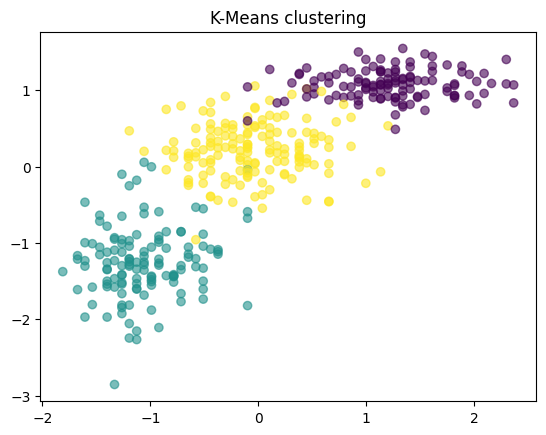

In [33]:
plt.scatter(x_scaled[:,0],x_scaled[:,1],c=cdf['Cluster'],alpha=0.60)
plt.title("K-Means clustering")

***HEIRARCHICAL CLUSTERING***

In [34]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = hc.fit_predict(x_scaled)

In [35]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

x_pca = pca.fit_transform(x_scaled)

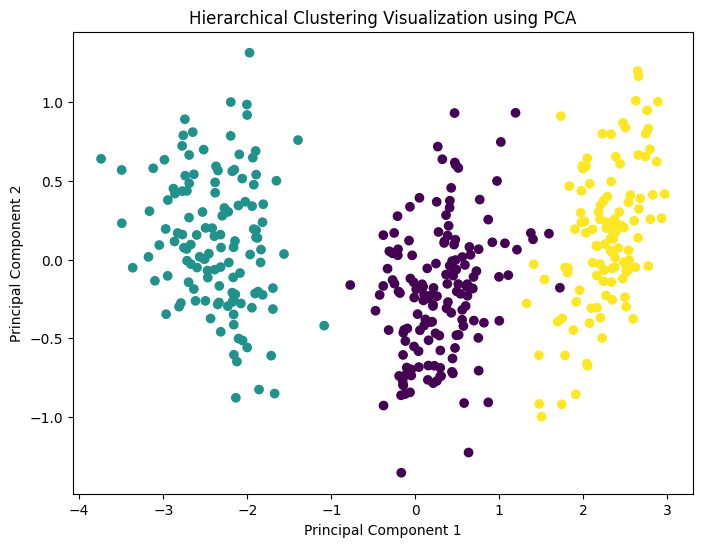

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=labels
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Clustering Visualization using PCA")

plt.show()

In [37]:
cdf['Heriarchical_Cluster'] = labels

In [38]:
cdf.head()

,StudentID,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct,SleepHours,ScreenTimeHours,Gender,Stream,ExtraCurricular,Age,BacklogCount,OptionalCounsellorNote,OptionalHostelBlock,Cluster,Heriarchical_Cluster
0,S2158,4.5,97.0,84.0,88.9,7.5,2.8,Male,Commerce,0,21.0,0,Needs Follow-Up,A,0,2
1,S2249,5.6,93.1,80.0,87.3,8.0,2.6,Male,Science,0,17.0,0,Needs Follow-Up,A,0,2
2,S2146,2.0,76.8,64.0,76.0,7.2,3.0,Male,Commerce,1,21.0,1,Needs Follow-Up,A,2,0
3,S2297,1.6,88.2,68.0,87.5,7.4,6.0,Male,Commerce,0,22.0,1,Needs Follow-Up,A,2,0
4,S2232,4.6,93.5,85.0,89.9,6.9,1.7,Male,Commerce,1,20.0,0,Needs Follow-Up,A,0,2


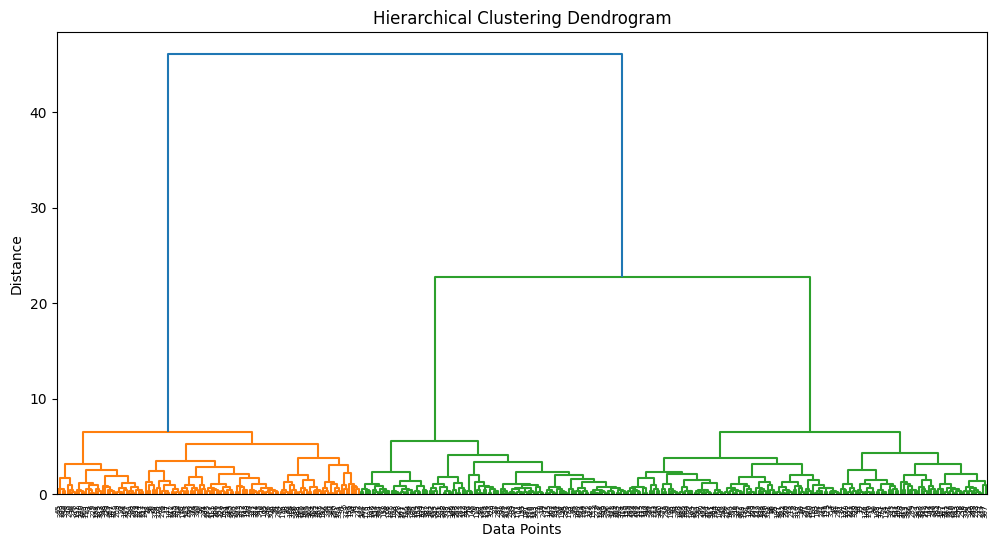

In [39]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(x_scaled, method='ward')

plt.figure(figsize=(12,6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

In [40]:
from sklearn.metrics import silhouette_score

for k in range(2, 7):
    hc = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = hc.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)

    print(k, score)

2 0.5820340203480362
3 0.5464967784864752
4 0.399136405620097
5 0.28460787028910745
6 0.20833036110733905


***Here best k value from Dendogram and shilouette score is k=2***

In [41]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

labels = hc.fit_predict(x_scaled)

cdf['Cluster'] = labels

In [42]:
cdf.Cluster.value_counts()

Cluster
0    265
1    128
Name: count, dtype: int64

***Profiling CLuster***

In [43]:
cdf.groupby('Cluster')[X.columns].mean()

,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct
Cluster,,,,
0,3.388302,85.237736,73.89434,81.220943
1,1.107813,56.966406,41.87500,45.838281


***From Business Perspective taking k =3 would give more information like categroy of student 
1) Excellent 

2) average 

3) Poor

In [44]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = hc.fit_predict(x_scaled)

cdf['Cluster'] = labels

In [45]:
cdf.groupby('Cluster')[X.columns].mean()

,StudyHoursPerDay,AttendancePct,PrevExamScore,AssignmentCompletionPct
Cluster,,,,
0,2.607237,79.798684,65.730263,74.666118
1,1.107813,56.966406,41.875000,45.838281
2,4.438938,92.553982,84.876106,90.038053


Here CLUSTER 0 : Average Student : Studiied for 2.5 hrs got Average mark in previous exam

    Cluster 1: Poor student : Studied for 1.3 hrs got poor marks in exam 

    Cluster 2: Brilliant student : Student Studied for 4.5 hrs score distinctiom marks in exam 

***Findings : More the Stud Hours More the Score in exam is***